# Greedy anomaly detection

In [1]:
%matplotlib inline

# Import the analysis and plotting tools and record the package version.
import numpy as np
import matplotlib.pyplot as plt
import nahiku
from nahiku import Nahiku
print(f"Nāhiku {nahiku.__version__}")

# Set the display resolution and simplify plot borders.
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

/tmp/nahiku-02/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Nāhiku 0.2.0


Metric growth: {'matched_events': 2, 'detected_events': 2, 'true_events': 2, 'false_positives': 0, 'missed_events': 0, 'precision': 1.0, 'recall': 1.0} threshold
LOO / threshold growth: {'matched_events': 2, 'detected_events': 2, 'true_events': 2, 'false_positives': 0, 'missed_events': 0, 'precision': 1.0, 'recall': 1.0} threshold


Adaptive scatter: [0.002731400613872587, 0.0016639063189556606, 0.0012147722683850991]
Metric flagged outside truth: 7 missed truth samples: 14
LOO flagged outside truth: 0 missed truth samples: 30
Adaptive flagged outside truth: 7 missed truth samples: 14


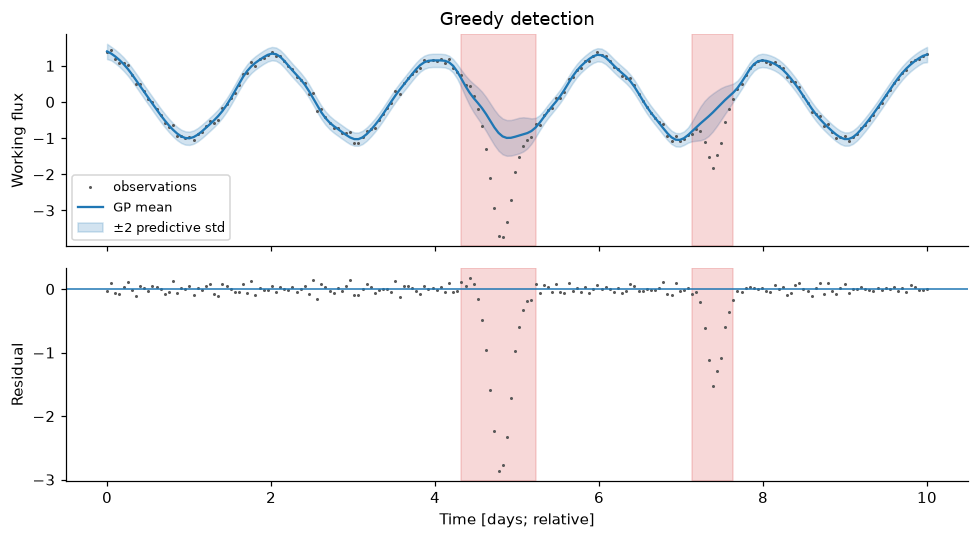

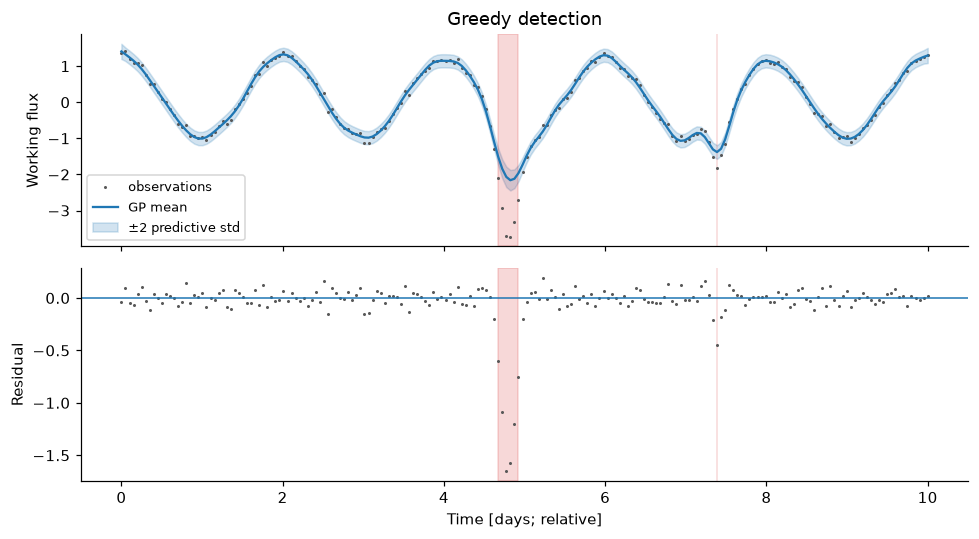

In [2]:
# Generate a reproducible periodic baseline with white measurement noise.
lc = Nahiku.from_synthetic_noise(duration=10, n_points=200, period=2,
                                 amplitude=0.3, white_noise=0.02, red_noise=0, seed=48)

# Inject two known dips so event recovery can be evaluated against their truth masks.
lc.inject_anomaly(center=4.8, width=0.12, depth=0.8, shape="gaussian")
lc.inject_anomaly(center=7.4, width=0.07, depth=0.45, shape="exocomet")

# Standardize observations and fit the baseline GP before searching for anomalies.
lc.standardize()
lc.fit_gp(period=2, length_scale=4, iterations=120)

# Allow a single strong seed: two adjacent samples need not both exceed the threshold.
# Search for negative dips at sigma=3; keep GP hyperparameters fixed during metric growth.
greedy = lc.greedy_search(sigma=3, len_deviant=1, direction="negative")
greedy.plot();

# Compare merged detected events with injected truth and inspect the stopping reason.
print("Metric growth:", lc.evaluate(greedy), greedy.settings["stop_reason"])

# Run an independent search using leave-one-out seeds and same-sign threshold growth.
# Restrict to negative events, enable gap barriers, and cap seeded events at 20.
loo = lc.greedy_search(seed_statistic="loo", len_deviant=1, growth="threshold",
                       sigma=4, grow_sigma=2, direction="negative", gap_factor=5,
                       max_events=20)
loo.plot();
print("LOO / threshold growth:", lc.evaluate(loo), loo.settings["stop_reason"])

# Run a third search that updates residual scatter after each accepted event.
# Inspect whether the scatter changes; earlier result objects remain independent.
adaptive = lc.greedy_search(sigma=3, len_deviant=1, direction="negative", update_threshold=True)
print("Adaptive scatter:", adaptive.settings["residual_variance_history"])

# Check event recovery, then separately quantify samples beyond or missing from truth support.
# Event-level precision and recall alone do not measure boundary accuracy.
for name, result in [("Metric", greedy), ("LOO", loo), ("Adaptive", adaptive)]:
    report = lc.evaluate(result)
    assert report["matched_events"] == 2 and report["false_positives"] == 0
    print(name, "flagged outside truth:", np.count_nonzero(result.mask & ~lc.truth_mask),
          "missed truth samples:", np.count_nonzero(lc.truth_mask & ~result.mask))


## Interpret the result

The metric-growth search, the leave-one-out (LOO) search with threshold growth, and the search with adaptive residual scatter each recover both injected events without additional detections. Each search uses `len_deviant=1`, allowing a single qualifying sample to seed an interval. Residual seeding uses `sigma=3`; LOO seeding uses `sigma=4` with `grow_sigma=2` for interval growth. The searches select negative deviations and hold GP hyperparameters fixed while updating conditional predictions.

Event-level precision and recall measure recovery of whole events. They do not measure boundary accuracy. Metric growth includes some samples outside the injected support, while threshold growth captures narrower portions of the events. The sample-level diagnostics report both extra flagged samples and missed truth samples. Detection sensitivity and false-alarm rates require evaluation across multiple signal shapes, noise realizations, and observing conditions.

`seed_statistic="residual"` uses ordinary posterior residuals and a threshold of `sigma * sqrt(flux_err**2 + var(abs(residual)))`. `len_deviant` requires a contiguous run above threshold and ranks runs by their minimum strength. Increasing it can reject isolated noise excursions but can also miss events whose strongest residual occupies only one sample. With `seed_statistic="loo"`, the same run criterion applies to standardized leave-one-out residuals.

`growth="metric"` evaluates exclusions and keeps the last strictly improving interval. `growth_metric` selects `"mll"`, `"nlpd"`, `"msll"`, or `"rmse"`. `expansion_param` controls samples added to each edge. All losses are minimized; MLL uses the negative prior marginal log likelihood per retained observation. `growth="threshold"` extends through same-sign neighbors above `grow_sigma`. Metric growth can include weak event wings, while threshold growth can truncate them; boundary accuracy should be assessed with injection/recovery tests.

`direction="both"` is the default; `"negative"` or `"positive"` restricts eligible seeds. `gap_factor=None` disables gap barriers; a positive value prevents seeds and growth from crossing gaps larger than that multiple of the median cadence. `max_events=None` runs until no eligible seed remains, subject to retaining at least `min_remaining` observations (default 3). An integer adds an event-count limit.

`update_threshold=False` freezes the initial residual scatter. Setting it to `True` recomputes scatter after each accepted event, as shown by the adaptive search's variance history. LOO uses current conditional uncertainties and does not accept this option. Results record the stopping reason and residual-scatter history where applicable.

`refit=True` retrains each metric-growth trial or each accepted threshold-grown event. `warm_initialization=True` starts from the preceding accepted parameters; `False` uses fresh initialization. Optimizer state is new on each refit. Torch is the default conditioning backend; `backend="numpy"` selects SciPy. Each returned result remains independent of subsequent searches.

Consult the API reference for parameter and return-value details.